In [9]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

def purchase_probability(price):
    price = np.asarray(price, dtype=float)
    return (
        0.55 * np.exp(-np.logaddexp(0.0, (price - 13.9) / 0.8))
        + 0.30 * np.exp(-np.logaddexp(0.0, (price - 30.9) / 1.2))
        + 0.15 * np.exp(-np.logaddexp(0.0, (price - 58.4) / 1.8))
    )

def sales(price=14.0, rng=None, mean_customers=30):
    price = float(price)
    if not np.isfinite(price):
        raise ValueError("price must be finite")
    if price < 0:
        raise ValueError("price must be nonnegative")
    mean_customers = float(mean_customers)
    if not np.isfinite(mean_customers) or mean_customers < 0:
        raise ValueError("mean_customers must be finite and nonnegative")
    rng = np.random.default_rng(rng)
    customer_count = rng.poisson(mean_customers)
    probability = purchase_probability(price)
    return rng.binomial(1, probability, size=customer_count).astype(np.int8)

In [10]:
def estimate_gradient(price, *, step=1.0, mean_customers=300, rng=None):
    if step <= 0:
        raise ValueError("step must be positive")
    rng = np.random.default_rng(rng)
    price = float(np.clip(price, 0, 75))
    price_low = max(0, price - step)
    price_high = min(75, price + step)
    low = price_low * sales(price_low, mean_customers=mean_customers, rng=rng)
    high = price_high * sales(price_high, mean_customers=mean_customers, rng=rng)
    if min(len(low), len(high)) < 2:
        raise ValueError("Need at least two customers per arm; increase mean_customers.")

    difference = high.mean() - low.mean()
    se = np.sqrt(low.var(ddof=1) / len(low) + high.var(ddof=1) / len(high))
    gap = price_high - price_low
    return {
        "price": price,
        "gradient": difference / gap,
        "gradient_se": se / gap,
        "ci_low": (difference - 1.645 * se) / gap,
        "ci_high": (difference + 1.645 * se) / gap,
        "customers": len(low) + len(high),
        "revenue": low.sum() + high.sum(),
    }

In [11]:
def gradient_ascent(start_price, iterations=80, step=1.0,
                    learning_rate=2.0, mean_customers=300, seed=100):
    if iterations < 1:
        raise ValueError("iterations must be at least 1")
    search_rng = np.random.default_rng(seed)
    price = float(np.clip(start_price, 0, 75))
    records = []
    for iteration in range(iterations):
        estimate = estimate_gradient(price, step=step,
                                     mean_customers=mean_customers, rng=search_rng)
        rate = learning_rate / np.sqrt(iteration + 1)
        move = np.clip(rate * estimate["gradient"], -2.0, 2.0)
        next_price = float(np.clip(price + move, 0, 75))
        records.append({"iteration": iteration + 1, **estimate,
                        "learning_rate": rate, "next_price": next_price})
        price = next_price
    return pd.DataFrame(records)

In [12]:
lab_rng = np.random.default_rng(42)

grid = np.arange(2, 71, 2.0)
grid_data = [p * sales(p, mean_customers=200, rng=lab_rng) for p in grid]
grid_results = pd.DataFrame({
    "price": grid,
    "customers": [len(d) for d in grid_data],
    "revenue": [d.sum() for d in grid_data],
    "rev_per_customer": [d.mean() for d in grid_data],
})
best_grid_price = grid_results.loc[grid_results["rev_per_customer"].idxmax(), "price"]

path = gradient_ascent(start_price=best_grid_price, iterations=30, step=1.0,
                       learning_rate=2.0, mean_customers=300, seed=42)
optimal_price = path["next_price"].iloc[-1]

total_customers = grid_results["customers"].sum() + path["customers"].sum()
total_revenue = grid_results["revenue"].sum() + path["revenue"].sum()
print(f"Best grid price: {best_grid_price:.2f}")
print(f"Optimal price found: {optimal_price:.2f}")
print(f"Customers experimented on: {total_customers}")
print(f"Revenue during experiments: {total_revenue:,.2f}")
print(f"Revenue per customer: {total_revenue / total_customers:.3f}")
print(f"Share of optimal profit captured: {total_revenue / (total_customers * 11.925):.1%}")

Best grid price: 26.00
Optimal price found: 27.59
Customers experimented on: 24969
Revenue during experiments: 253,836.02
Revenue per customer: 10.166
Share of optimal profit captured: 85.2%


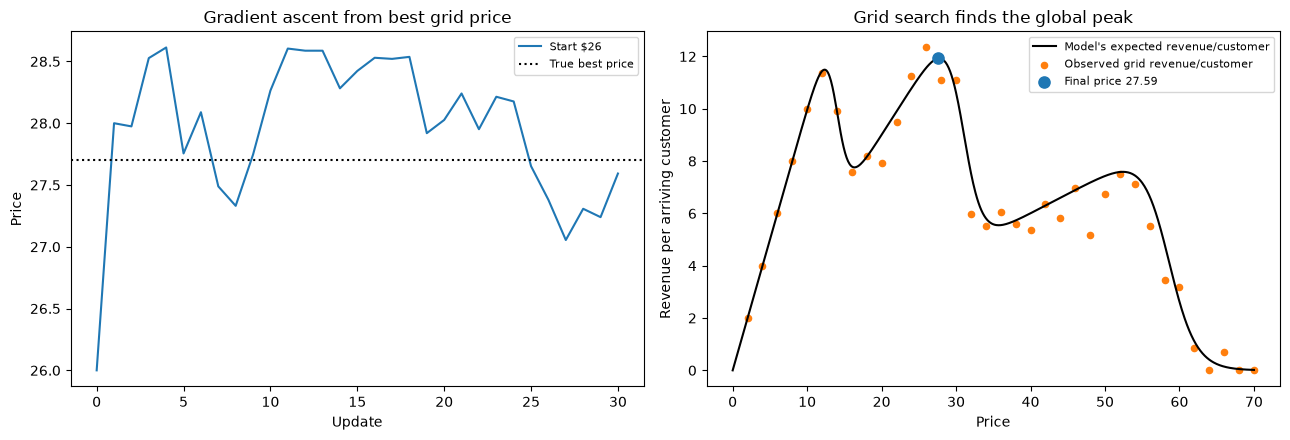

,start_price,final_price,search_customers,validation_customers,validation_revenue_per_customer,validation_se
0,26.0,27.593,24969,10036,11.965,0.137


In [ ]:
# From UU inference
price_curve = np.linspace(0, 70, 701)
expected_revenue_per_customer = price_curve * purchase_probability(price_curve)
true_best_price = price_curve[np.argmax(expected_revenue_per_customer)]
prices = np.r_[best_grid_price, path["next_price"].to_numpy()]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(np.arange(len(prices)), prices, color="C0", label=f"Start ${best_grid_price:g}")
axes[0].axhline(true_best_price, color="black", linestyle=":", label="True best price")
axes[0].set(xlabel="Update", ylabel="Price", title="Gradient ascent from best grid price")
axes[0].legend(fontsize=8)

axes[1].plot(price_curve, expected_revenue_per_customer,
             color="black", label="Model's expected revenue/customer")
axes[1].scatter(grid_results["price"], grid_results["rev_per_customer"],
                color="C1", s=20, label="Observed grid revenue/customer")
axes[1].scatter(optimal_price, optimal_price * purchase_probability(optimal_price),
                color="C0", s=65, zorder=3, label=f"Final price {optimal_price:.2f}")
axes[1].set(xlabel="Price", ylabel="Revenue per arriving customer",
            title="Grid search finds the global peak")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

validation = optimal_price * sales(optimal_price, mean_customers=10_000,
                                   rng=np.random.default_rng(9001))
pd.DataFrame([{
    "start_price": best_grid_price,
    "final_price": optimal_price,
    "search_customers": int(total_customers),
    "validation_customers": len(validation),
    "validation_revenue_per_customer": validation.mean(),
    "validation_se": validation.std(ddof=1) / np.sqrt(len(validation)),
}]).round(3)